In [1]:
from segment_anything import SamAutomaticMaskGenerator, sam_model_registry,SamPredictor
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [2]:
def show_mask(mask, ax, random_color=False):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    mask_image = mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    ax.imshow(mask_image)
    
def show_points(coords, labels, ax, marker_size=375):
    pos_points = coords[labels==1]
    neg_points = coords[labels==0]
    ax.scatter(pos_points[:, 0], pos_points[:, 1], color='green', marker='*', s=marker_size, edgecolor='white', linewidth=1.25)
    ax.scatter(neg_points[:, 0], neg_points[:, 1], color='red', marker='*', s=marker_size, edgecolor='white', linewidth=1.25)   
    
def show_box(box, ax):
    x0, y0 = box[0], box[1]
    w, h = box[2] - box[0], box[3] - box[1]
    ax.add_patch(plt.Rectangle((x0, y0), w, h, edgecolor='green', facecolor=(0,0,0,0), lw=2))    
    
def show_anns(anns):
    if len(anns) == 0:
        return
    sorted_anns = sorted(anns, key=(lambda x: x['area']), reverse=True)
    ax = plt.gca()
    ax.set_autoscale_on(False)
    polygons = []
    color = []
    for ann in sorted_anns:
        m = ann['segmentation']
        img = np.ones((m.shape[0], m.shape[1], 3))
        color_mask = np.random.random((1, 3)).tolist()[0]
        for i in range(3):
            img[:,:,i] = color_mask[i]
        ax.imshow(np.dstack((img, m*0.35)))

In [3]:
device = "cuda"
sam = sam_model_registry["vit_h"](checkpoint="/home/ehajizad/ss_learning/segment_anything_models/sam_vit_h_4b8939.pth")
sam.to(device=device)

predictor = SamPredictor(sam)
# mask_generator = SamAutomaticMaskGenerator(sam)

In [148]:
image = cv2.imread("/home/ehajizad/.avalanche/data/core50/core50_128x128_original/s1/o2/C_01_02_080.png")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
# masks = mask_generator.generate(image)
predictor.set_image(image)

In [98]:
# input_point = np.array([[64, 64], [40,40], [20,40], [100,100], [20,100], [40,80], [80,40], [30,70], [60,100], [80,80]])
# input_label = np.array([1,1,1,1,1,1,1,1,1,1])
input_point = np.array([[40, 20]])
input_label = np.array([1])

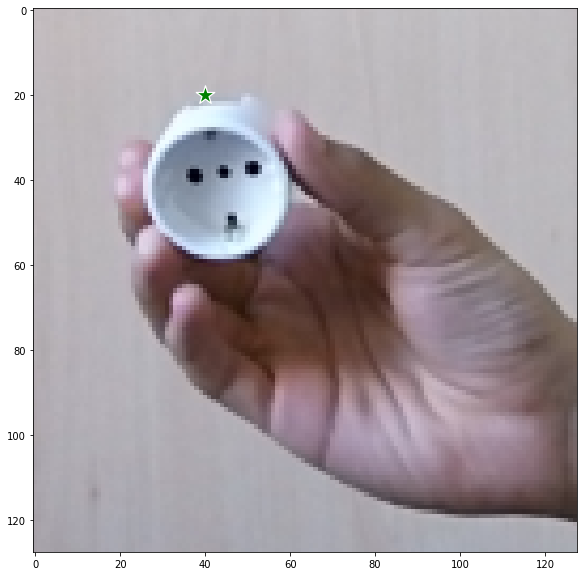

In [99]:
plt.figure(figsize=(10,10))
plt.imshow(image)
show_points(input_point, input_label, plt.gca())
plt.axis('on')
plt.show()  

In [100]:
input_box = np.array([20, 20, 108, 108])

In [101]:
masks, _, _ = predictor.predict(
    multimask_output=True,
    point_coords=None,
    point_labels=None,
    box=None,
)

In [102]:
masks.shape 

(3, 128, 128)

In [ ]:
for i, (mask, score) in enumerate(zip(masks, scores)):
    plt.figure(figsize=(10, 10))
    plt.imshow(image)
    show_mask(mask, plt.gca())
    show_box(input_box, plt.gca())
    plt.title(f"Mask {i+1}, Score: {score:.3f}", fontsize=18)
    plt.axis('off')
    plt.show()

In [4]:
image = cv2.imread("/home/ehajizad/.avalanche/data/core50/core50_128x128_original/s3/o2/C_03_02_130.png")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
# masks = mask_generator.generate(image)
predictor.set_image(image)

In [110]:
mask_generator_2 = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=18,
    # point_grids = [np.array([0.1,0.2,0.25,0.3,0.35,0.4,0.45,0.5,0.55,0.6,0.65,0.7,0.75,0.8,0.9])[:,None]],
    pred_iou_thresh=0.93,
    stability_score_thresh=0.93,
    box_nms_thresh=0.1,
    crop_n_layers=0,
    crop_n_points_downscale_factor=0,
    min_mask_region_area=200,  # Requires open-cv to run post-processing
)

In [111]:
masks = mask_generator_2.generate(image)

In [112]:
len(masks)

16

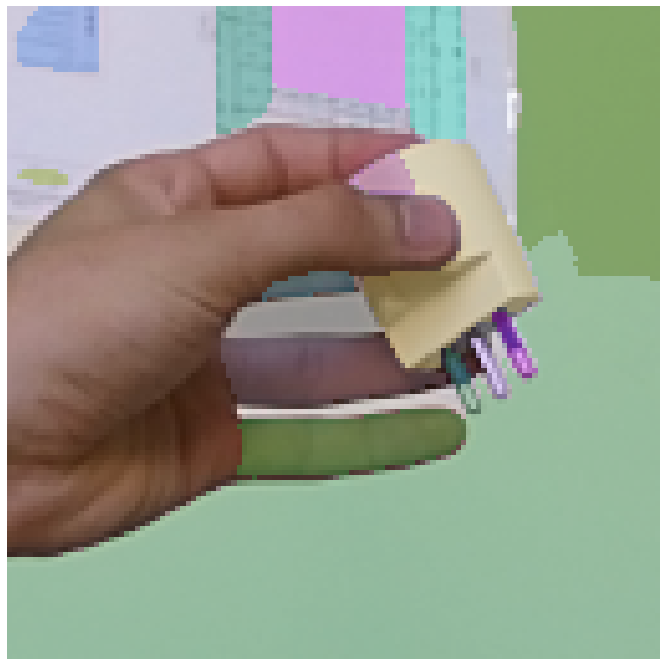

In [113]:
plt.figure(figsize=(12,12))
plt.imshow(image)
show_anns(masks)
plt.axis('off')
plt.show() 

In [ ]:
chosen_masks = []
scores = []
for i in range(len(masks)):
    iou = masks[i]["predicted_iou"]
    score =  masks[i]["stability_score"]
    mask = masks[i]["segmentation"]
    area = masks[i]["area"]
    if area>400 and area<1500:
        chosen_masks.append(mask)
        scores.append(score)
        
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    show_mask(mask, plt.gca())
    plt.title(f"Mask {i+1}, predicted_iou,{iou:.3f} Score: {score:.3f}, area: {area:.3f}", fontsize=18)
    plt.axis('off')
    plt.show()    
    
scores = np.array(scores)
winner_mask = chosen_masks[np.argmax(scores)]

# plt.figure(figsize=(10, 10))
# plt.imshow(image)
# show_mask(winner_mask, plt.gca())
# plt.title(f"Mask {i+1}, predicted_iou,{iou:.3f} Score: {score:.3f}, area: {area:.3f}", fontsize=18)
# plt.axis('off')
# plt.show()